<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Regularation_augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint : Techniques de régularisation – Augmentation des données et Dropout

# Objectif
Soumettre un court notebook ou script où vous démontrez votre compréhension de l’augmentation des données et du dropout en deep learning

## 1. Imports et chargement des données

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# normalisation des pixels entre 0 et 1
x_train = x_train / 255.0
x_test = x_test / 255.0

noms = ["avion", "voiture", "oiseau", "chat", "cerf",
        "chien", "grenouille", "cheval", "bateau", "camion"]

print("Train :", x_train.shape, "| Test :", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2189s 13us/step
Train : (50000, 32, 32, 3) | Test : (10000, 32, 32, 3)


## 2. Augmentation des données

J'utilise trois techniques d’augmentation  :
- `RandomFlip("horizontal")` : retourne l'image comme dans un miroir ;
- `RandomRotation(0.1)` : tourne l'image d'au plus 10 % d'un tour, soit ±36° ;
- `RandomZoom(0.1)` : zoome ou dézoome d'au plus 10 %.


In [2]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

### Images originales et images augmentées

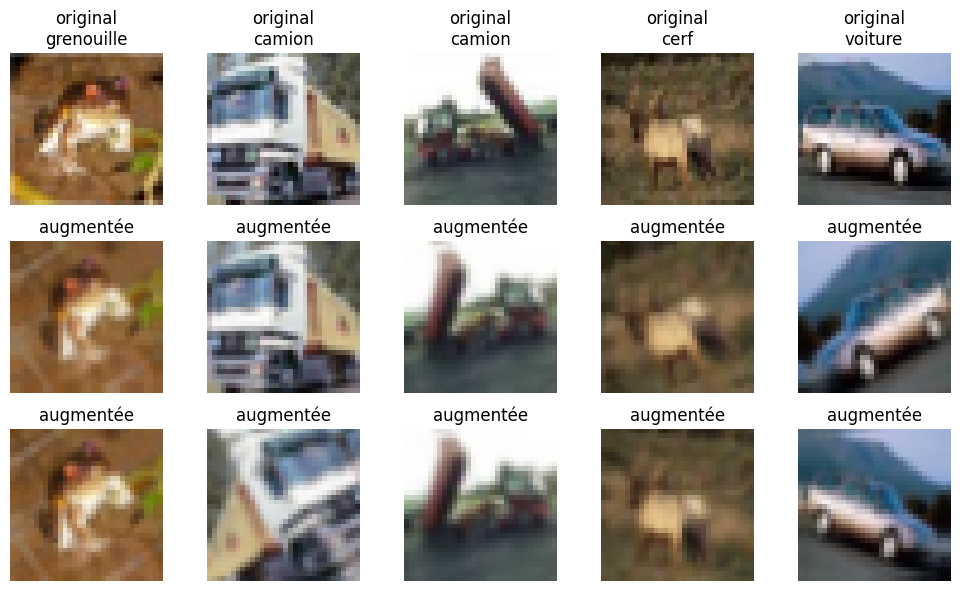

In [3]:
exemples = x_train[:5]

plt.figure(figsize=(10, 6))
for ligne in range(3):
    if ligne == 0:
        images = exemples
    else:
        images = augmentation(exemples, training=True).numpy()
    for i in range(5):
        plt.subplot(3, 5, ligne * 5 + i + 1)
        plt.imshow(np.clip(images[i], 0, 1))
        plt.axis("off")
        if ligne == 0:
            plt.title("original\n" + noms[y_train[i][0]])
        else:
            plt.title("augmentée")
plt.tight_layout()
plt.show()

## 3. CNN avec dropout

Je mets le dropout à **deux endroits** :
- `Dropout(0.25)` après les convolutions : 25 % des valeurs sont mises à zéro au hasard ;
- `Dropout(0.5)` après la couche `Dense(128)` : c'est la couche qui a le plus de paramètres, donc celle qui risque le plus de surapprendre.

In [4]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    augmentation,

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),          # dropout n°1

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),           # dropout n°2

    layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Entraînement

In [5]:
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

historique = model.fit(x_train, y_train,
                       epochs=5,
                       batch_size=64,
                       validation_data=(x_test, y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.3694 - loss: 1.7335 - val_accuracy: 0.5019 - val_loss: 1.3749
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4649 - loss: 1.4895 - val_accuracy: 0.5600 - val_loss: 1.2438
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5014 - loss: 1.4006 - val_accuracy: 0.5708 - val_loss: 1.2055
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5166 - loss: 1.3490 - val_accuracy: 0.5903 - val_loss: 1.1443
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5335 - loss: 1.3132 - val_accuracy: 0.5963 - val_loss: 1.1462


### Perte et précision par époque

Époque | perte train | préc. train | perte val | préc. val
     1 |      1.7335 |      36.94% |    1.3749 |    50.19%
     2 |      1.4895 |      46.49% |    1.2438 |    56.00%
     3 |      1.4006 |      50.14% |    1.2055 |    57.08%
     4 |      1.3490 |      51.66% |    1.1443 |    59.03%
     5 |      1.3132 |      53.35% |    1.1462 |    59.63%


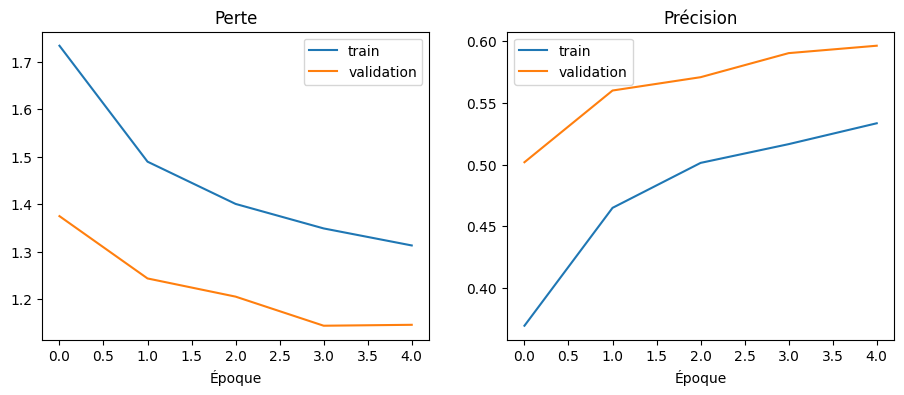

In [6]:
h = historique.history
print("Époque | perte train | préc. train | perte val | préc. val")
for e in range(len(h["loss"])):
    print(f"{e + 1:>6} | {h['loss'][e]:>11.4f} | {h['accuracy'][e]:>11.2%} | "
          f"{h['val_loss'][e]:>9.4f} | {h['val_accuracy'][e]:>9.2%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h["loss"], label="train")
ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Perte"); ax[0].set_xlabel("Époque"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train")
ax[1].plot(h["val_accuracy"], label="validation")
ax[1].set_title("Précision"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.show()

## 5. Courte analyse

J'ai choisi le retournement horizontal, la rotation et le zoom parce qu'ils produisent des images encore réalistes pour CIFAR-10 : un chat vu en miroir, un peu penché ou un peu plus proche reste un chat, alors qu'un retournement vertical aurait donné des voitures à l'envers. Le dropout empêche le réseau de compter sur quelques neurones en particulier. La précision d'entraînement monte donc plus lentement, et elle reste souvent un peu sous la précision de validation, puisque le dropout et l'augmentation ne sont actifs que pendant l'entraînement. En contrepartie, l'écart entre les courbes reste faible et le modèle surapprend peu, alors qu'un CNN sans régularisation se met vite à mémoriser le jeu d'entraînement.